[![Query.Farm](assets/query-farm-strata-sun.svg)](https://query.farm/)

[![VGI](assets/vgi-logo.png)](https://query.farm/vgi/)

# Compare regional income on compatible scales

Does the region with the largest total income also have the highest income per person? Before comparing, we must interpret the unit exponent, join the population denominator, and preserve suppressed values. The real BEA worker parses the response; SQL performs the conversions and comparison.

**All observations are synthetic.** A companion HTTP server returns a small BEA-shaped response for four invented regions: Aster, Briar, Cedar and Dune. Their leading-zero identifiers are fictional, not real geography codes. The response format follows the project’s existing API fixture. No BEA API key or live economic data is used. The numerical rankings illustrate data handling, not real regional performance.

## Select a source year

`YEAR` is either 2023 or 2024; the default is 2024. It selects a different fixed synthetic response at the source. Restart and run all after editing it. The final experiment switches to 2023 and checks both the rankings and which income observation is suppressed.

In [1]:
YEAR = 2024  # synthetic annual observation period; integer 2023 or 2024

In [2]:
import os

import haybarn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from notebook_support import COLORS, finish, prose, theme
from synthetic_api import start_fixture

if type(YEAR) is not int or YEAR not in (2023, 2024):
    raise ValueError("YEAR must be the integer 2023 or 2024.")
fixture_server = start_fixture()
os.environ["BEA_API_BASE_URL"] = f"http://127.0.0.1:{fixture_server.server_port}/api/data"
os.environ["BEA_ALLOW_INSECURE_HTTP"] = "1"
theme()
connection = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql connection

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-bea/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-bea/notebooks/pyproject.toml.

## Attach the pinned worker

The literal Git launcher runs the published source with SDK 0.51.1, independently of this repository’s root environment. The companion starts a loopback server and uses the worker’s supported endpoint override. The all-zero GUID below is a public, invalid test key used only by that fixture; it is never sent to BEA. See the [README](README.md) for setup and the fixture boundary.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'bea' (TYPE vgi,
    LOCATION 'uvx --python 3.13 --with vgi-python==0.51.1 --from git+https://github.com/Query-farm/vgi-bea@09bf4ef62c002c1cd4b1eea704cdff1c4821e392 vgi-bea-worker'
);
CREATE SECRET synthetic_bea (
    TYPE bea_api, API_KEY '00000000-0000-0000-0000-000000000000'
);

,Success


## Retrieve income and population together

The query requests both line codes for the chosen year and materializes the response once. `value_text` preserves commas and suppression markers; `value` is numeric where available. The worker returns `unit_multiplier` as metadata and **does not apply it** to `value`. Geography identifiers remain text.

In [4]:
%%sql
CREATE TABLE reported AS
SELECT * FROM bea.main.data('Regional',
    '{"TableName":"SAINC1","LineCode":"1,2","GeoFIPS":"STATE","Year":"{{YEAR}}"}'
);

SELECT time_period, geo_fips, geo_name, line_number, line_description,
       value_text, value, unit, unit_multiplier
FROM reported ORDER BY geo_fips, line_number;

,time_period,geo_fips,geo_name,line_number,line_description,value_text,value,unit,unit_multiplier
0,2024,00001,Aster,1,Personal income,"15,000.0",15000.0,USD,6
1,2024,00001,Aster,2,Population,"250,000",250000.0,Persons,0
2,2024,00002,Briar,1,Personal income,"9,000.0",9000.0,USD,6
3,2024,00002,Briar,2,Population,"100,000",100000.0,Persons,0
4,2024,00003,Cedar,1,Personal income,"20,000.0",20000.0,USD,6
5,2024,00003,Cedar,2,Population,"500,000",500000.0,Persons,0
6,2024,00004,Dune,1,Personal income,(D),NaN,USD,6
7,2024,00004,Dune,2,Population,"300,000",300000.0,Persons,0


In [5]:
%%sql
SELECT DISTINCT json_extract_string(notes_json, '$[0].NoteText') AS source_note
FROM reported;

,source_note
0,Entire response is synthetic. (D) marks a deli...


## Normalize units while preserving NULLs

For the income line, the response says USD with exponent 6: multiply the reported numeric value by one million to obtain USD. Population has exponent 0 and remains in persons. The shared conversion is `value × 10^unit_multiplier`; its unit stays attached. SQL NULL propagation preserves the suppressed income as unavailable.

In [6]:
%%sql
CREATE TABLE normalized AS
SELECT *, value * power(10, unit_multiplier) AS base_value
FROM reported;

SELECT geo_name, line_description, unit, unit_multiplier, value AS reported_value,
       base_value, value_text
FROM normalized ORDER BY geo_fips, line_number;

,geo_name,line_description,unit,unit_multiplier,reported_value,base_value,value_text
0,Aster,Personal income,USD,6,15000.0,1.500000e+10,"15,000.0"
1,Aster,Population,Persons,0,250000.0,2.500000e+05,"250,000"
2,Briar,Personal income,USD,6,9000.0,9.000000e+09,"9,000.0"
3,Briar,Population,Persons,0,100000.0,1.000000e+05,"100,000"
4,Cedar,Personal income,USD,6,20000.0,2.000000e+10,"20,000.0"
5,Cedar,Population,Persons,0,500000.0,5.000000e+05,"500,000"
6,Dune,Personal income,USD,6,NaN,NaN,(D)
7,Dune,Population,Persons,0,300000.0,3.000000e+05,"300,000"


## Join the denominator at the geography grain

Pivot the two lines by geography and period, retaining their original income text for diagnostics. Income per person is total income in USD divided by population in persons. It is available only when income is known and population is positive. No suppressed value is replaced with zero.

In [7]:
%%sql
CREATE TABLE comparison AS
WITH paired AS (
    SELECT time_period, geo_fips, geo_name,
           max(CASE WHEN line_number = '1' THEN base_value END) AS income_usd,
           max(CASE WHEN line_number = '1' THEN value_text END) AS income_text,
           max(CASE WHEN line_number = '2' THEN base_value END) AS population
    FROM normalized GROUP BY time_period, geo_fips, geo_name
)
SELECT *,
       income_usd / 1000000000.0 AS income_billion_usd,
       CASE WHEN population > 0 THEN income_usd / population END AS income_per_person_usd
FROM paired;

CREATE TABLE ranked AS
SELECT *,
       CASE WHEN income_usd IS NOT NULL
            THEN rank() OVER (ORDER BY income_usd DESC NULLS LAST) END AS income_rank,
       CASE WHEN income_per_person_usd IS NOT NULL
            THEN rank() OVER (ORDER BY income_per_person_usd DESC NULLS LAST) END AS per_person_rank
FROM comparison;

,Count


In [8]:
%%sql regions <<
SELECT geo_fips, geo_name, income_billion_usd, population, income_per_person_usd,
       income_text, income_rank, per_person_rank
FROM ranked ORDER BY income_rank NULLS LAST, geo_name;

In [9]:
display(regions)

,geo_fips,geo_name,income_billion_usd,population,income_per_person_usd,income_text,income_rank,per_person_rank
0,00003,Cedar,20.0,500000.0,40000.0,"20,000.0",1,3
1,00001,Aster,15.0,250000.0,60000.0,"15,000.0",2,2
2,00002,Briar,9.0,100000.0,90000.0,"9,000.0",3,1
3,00004,Dune,NaN,300000.0,NaN,(D),<NA>,<NA>


In [10]:
%%sql availability <<
SELECT count(*) AS regions,
       count(income_usd) AS income_available,
       count(income_per_person_usd) AS comparable,
       string_agg(geo_name, ', ' ORDER BY geo_name)
           FILTER (WHERE income_usd IS NULL) AS unavailable_regions
FROM comparison;

In [11]:
a = availability.iloc[0]
prose(
    f"For synthetic **{YEAR}**, income is available for **{int(a.income_available)} of "
    f"{int(a.regions)} regions**, and **{int(a.comparable)}** have an income-per-person estimate. "
    f"Income is unavailable for **{a.unavailable_regions}**. Those regions stay visible but receive no numerical rank."
)

For synthetic **2024**, income is available for **3 of 4 regions**, and **3** have an income-per-person estimate. Income is unavailable for **Dune**. Those regions stay visible but receive no numerical rank.

## Compare total income

The first chart uses billions of USD, after the base-unit conversion. Missing income is labeled explicitly without drawing a zero-length bar. Colors identify the same invented region in both charts.

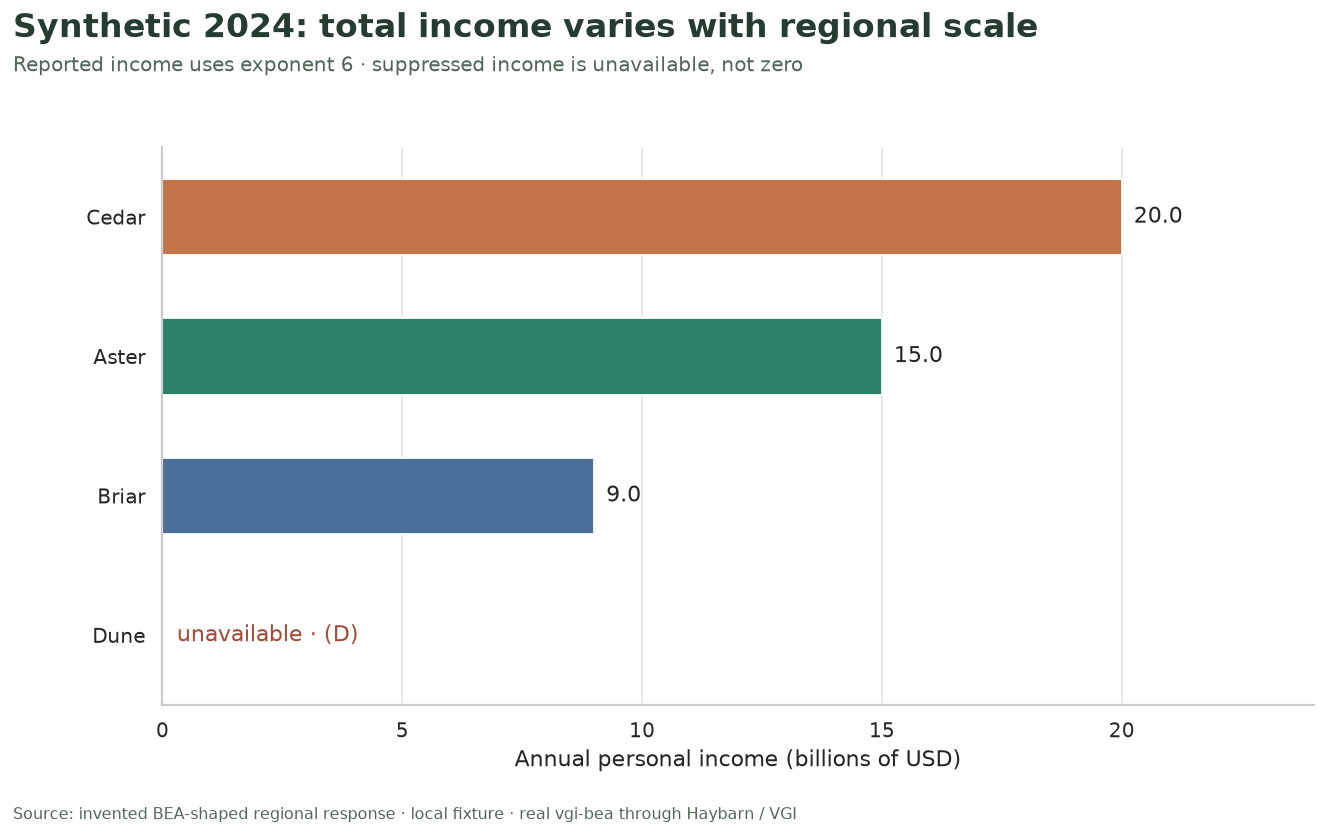

In [12]:
fig, ax = plt.subplots(figsize=(11.5, 6.5))
y = np.arange(len(regions))
valid = regions.income_billion_usd.notna()
ax.barh(
    y[valid],
    regions.loc[valid, "income_billion_usd"],
    color=[COLORS[x] for x in regions.loc[valid, "geo_name"]],
    height=0.55,
)
for i, row in regions.iterrows():
    if pd.notna(row.income_billion_usd):
        ax.text(row.income_billion_usd + 0.25, i, f"{row.income_billion_usd:,.1f}", va="center")
    else:
        ax.text(0.3, i, f"unavailable · {row.income_text}", va="center", color="#a34b36")
ax.set_yticks(y, regions.geo_name)
ax.set_ylim(len(y) - 0.5, -0.5)
ax.set_xlim(0, float(regions.income_billion_usd.max()) * 1.2)
ax.set_xlabel("Annual personal income (billions of USD)")
ax.grid(axis="y", visible=False)
finish(
    fig,
    f"Synthetic {YEAR}: total income varies with regional scale",
    "Reported income uses exponent 6 · suppressed income is unavailable, not zero",
    f"total-income-{YEAR}.png",
)

## Compare income per person

Reordering by the population-adjusted value can change the ranking. This is an aggregate ratio; it does not describe the median person, household income distribution or a causal effect of population.

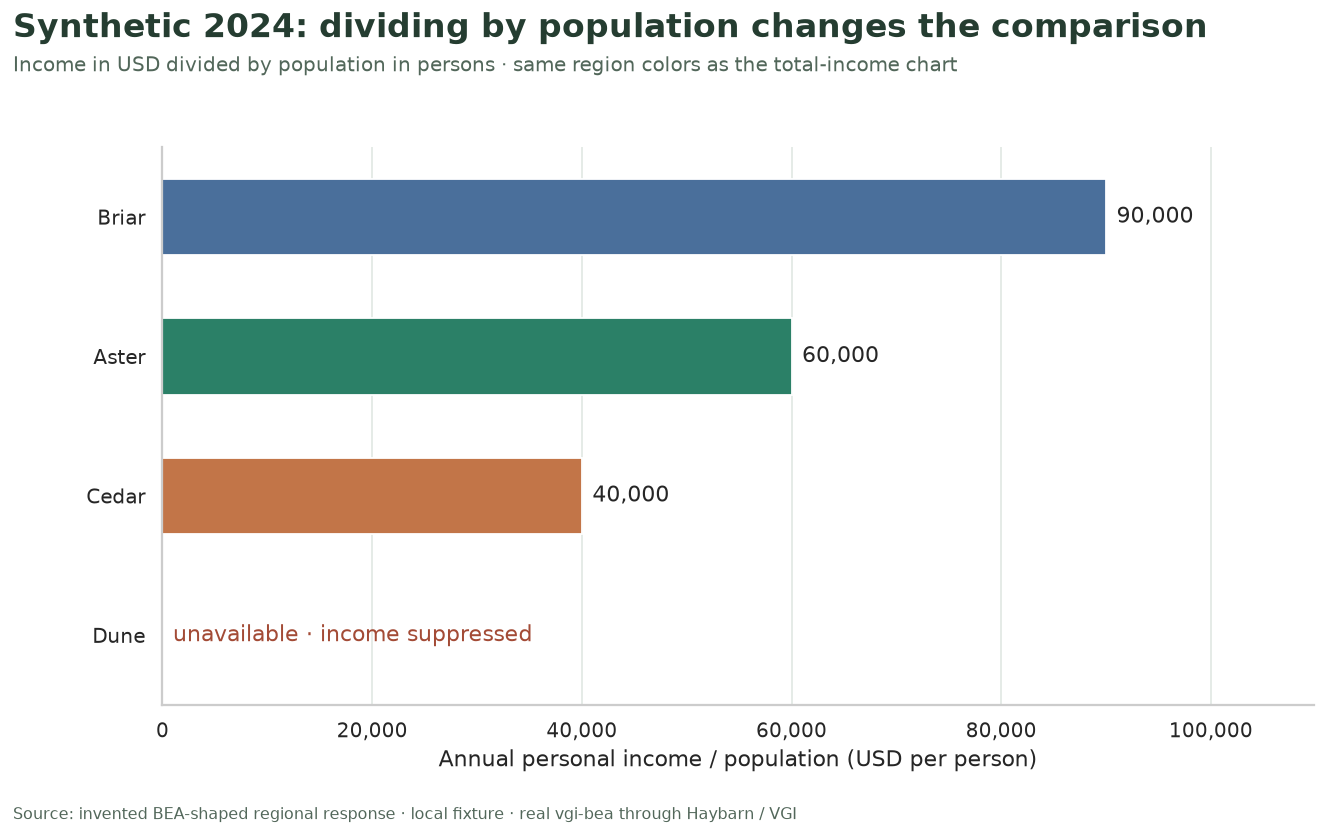

In [13]:
per_person = regions.sort_values("per_person_rank", na_position="last").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11.5, 6.5))
y = np.arange(len(per_person))
valid = per_person.income_per_person_usd.notna()
ax.barh(
    y[valid],
    per_person.loc[valid, "income_per_person_usd"],
    color=[COLORS[x] for x in per_person.loc[valid, "geo_name"]],
    height=0.55,
)
for i, row in per_person.iterrows():
    if pd.notna(row.income_per_person_usd):
        ax.text(row.income_per_person_usd + 1000, i, f"{row.income_per_person_usd:,.0f}", va="center")
    else:
        ax.text(1000, i, "unavailable · income suppressed", va="center", color="#a34b36")
ax.set_yticks(y, per_person.geo_name)
ax.set_ylim(len(y) - 0.5, -0.5)
ax.set_xlim(0, float(per_person.income_per_person_usd.max()) * 1.22)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:,.0f}"))
ax.set_xlabel("Annual personal income / population (USD per person)")
ax.grid(axis="y", visible=False)
finish(
    fig,
    f"Synthetic {YEAR}: dividing by population changes the comparison",
    "Income in USD divided by population in persons · same region colors as the total-income chart",
    f"income-per-person-{YEAR}.png",
)

In [14]:
total_leader = regions.loc[regions.income_rank == 1].iloc[0]
person_leader = regions.loc[regions.per_person_rank == 1].iloc[0]
prose(
    f"**{total_leader.geo_name}** leads available total income at "
    f"**{total_leader.income_billion_usd:,.1f} billion USD**. "
    f"**{person_leader.geo_name}** leads income per person at "
    f"**{person_leader.income_per_person_usd:,.0f} USD**, with a population of "
    f"**{person_leader.population:,.0f}**. "
    "These rankings apply only to the available synthetic observations. "
    "Suppression prevents a complete regional ranking."
)

**Cedar** leads available total income at **20.0 billion USD**. **Briar** leads income per person at **90,000 USD**, with a population of **100,000**. These rankings apply only to the available synthetic observations. Suppression prevents a complete regional ranking.

## Check the grain, units and availability

The pivot assumes one observation per geography, period and line. These checks detect duplicated inputs, incompatible units, incomplete pairs, and any suppressed income that accidentally acquired a numerical value. The final check ensures the denominator rule matches the displayed availability.

In [15]:
%%sql checks <<
SELECT
    (SELECT count(*) FROM (
        SELECT geo_fips, time_period, line_number FROM reported
        GROUP BY geo_fips, time_period, line_number HAVING count(*) != 1
    )) AS duplicate_grain,
    (SELECT count(*) FROM reported WHERE
        NOT ((line_number = '1' AND unit = 'USD' AND unit_multiplier = 6)
          OR (line_number = '2' AND unit = 'Persons' AND unit_multiplier = 0))
        OR unit IS NULL OR unit_multiplier IS NULL) AS unexpected_units,
    (SELECT count(*) FROM (
        SELECT geo_fips, time_period FROM reported
        GROUP BY geo_fips, time_period HAVING count(DISTINCT line_number) != 2
    )) AS incomplete_pairs,
    (SELECT count(*) FROM comparison WHERE income_text = '(D)' AND income_usd IS NOT NULL) AS lost_suppression,
    (SELECT count(*) FROM comparison WHERE
        (income_per_person_usd IS NOT NULL) IS DISTINCT FROM
        (coalesce(income_usd IS NOT NULL AND population > 0, false))) AS ratio_availability_gap;

In [16]:
display(checks)
assert (checks.iloc[0] == 0).all(), "A comparison assumption failed."
assert regions.income_rank.notna().sum() == int(a.income_available)
assert regions.per_person_rank.notna().sum() == int(a.comparable)
prose("The source grain, unit assumptions, suppression handling and ranking availability reconcile.")

,duplicate_grain,unexpected_units,incomplete_pairs,lost_suppression,ratio_availability_gap
0,0,0,0,0,0


The source grain, unit assumptions, suppression handling and ranking availability reconcile.

## Experiment: request the other year

Change **`YEAR = 2024` to `2023`**, restart and run all. Predict that the available total-income leader may change, while the income-per-person leader can remain the same. Compare the raw `value_text` table, which region is unavailable, and both charts.

The synthetic fixture deliberately moves the suppressed income to another region. Comparing totals across these runs without matching the available geography set would confound a value change with a coverage change. These are observation periods, not publication dates or historical vintages. Reset **`YEAR = 2024`** for the default, or save the experiment separately with the runner.

In [17]:
connection.close()
fixture_server.shutdown()
fixture_server.server_close()

[![Query.Farm](assets/query-farm-strata-sun.svg)](https://query.farm/)